# 01 — Analyse exploratoire du corpus Solana V1

Semaine 1, jour 5. Entrée : `data/interim/solana_corpus_v1.parquet` produit par
`python -m cryptonews.data.build_corpus`.

Questions : volume et provenance, couverture temporelle, longueur des titres, termes
fréquents, effet du dédoublonnage, recouvrement avec DLT-Sentiment-News (risque de fuite).

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.feature_extraction.text import CountVectorizer

from cryptonews.config import PROJECT_ROOT, path, load_config
from cryptonews.viz import apply_style, save, SOURCE_COLORS, SERIES, INK_2, MUTED

apply_style()
pd.set_option("display.max_colwidth", 120)
df = pd.read_parquet(path("interim") / "solana_corpus_v1.parquet")
stats = json.loads((PROJECT_ROOT / "reports" / "corpus_v1_stats.json").read_text(encoding="utf-8"))
print(f"{len(df):,} articles | {df.published_at_utc.min():%Y-%m-%d} -> {df.published_at_utc.max():%Y-%m-%d}")
df.head(3)

14,953 articles | 2020-03-09 -> 2025-08-27


,doc_id,source_dataset,outlet,published_at_utc,title,description,description_from_body,url,solana_in_title,solana_terms,n_words,in_dlt,cv_coin_type,title_norm
0,cr_1d6b089d50bd,cryptovision,coindesk.com,2020-03-09 19:49:00+00:00,"Pitch Deck Says Solana Is Courting Dish Network, Kik for Its 'Web-Scale' Blockchain","Solana is looking to raise up to $12M at a $125M valuation, touting potential relationships with Dish and Kin in a p...",False,https://www.coindesk.com/markets/2020/03/09/pitch-deck-says-solana-is-courting-dish-network-kik-for-its-web-scale-bl...,True,Solana,13,False,Ripple,pitch deck says solana is courting dish network kik for its web scale blockchain
1,cr_fcd89b052541,cryptovision,coindesk.com,2020-04-15 23:00:00+00:00,Solana Blockchain Adds Korean Stablecoin Terra for Better Payments,"Solana is adding the Terra stablecoin in an effort to bring ""novel applications that require price-stable payments"" ...",False,https://www.coindesk.com/tech/2020/04/15/solana-blockchain-adds-korean-stablecoin-terra-for-better-payments,True,Solana,9,False,Bitcoin,solana blockchain adds korean stablecoin terra for better payments
2,cr_ab634c8ab707,cryptovision,cryptopanic.com,2020-05-11 15:00:00+00:00,"Cardano hardfork - buy the rumor, sell the news?","2021 was the year of the platform blockchain. Ethereum, Avalanche, and Solana deployed ecosystem updates that led to...",False,https://cryptopanic.com/news/8769674/Cardano-hardfork-buy-the-rumor-sell-the-news,False,,9,False,Cardano,cardano hardfork buy the rumor sell the news


## 1. Entonnoir de nettoyage

,articles,removed
Chargés (2 sources),417603,0
Titre non vide,417293,310
Date valide (2020–2025),393282,24011
Filtre Solana,24827,368455
Titre >= 3 mots,24818,9
Sans doublon exact,15340,9478
Sans quasi-doublon (7 j),14953,387


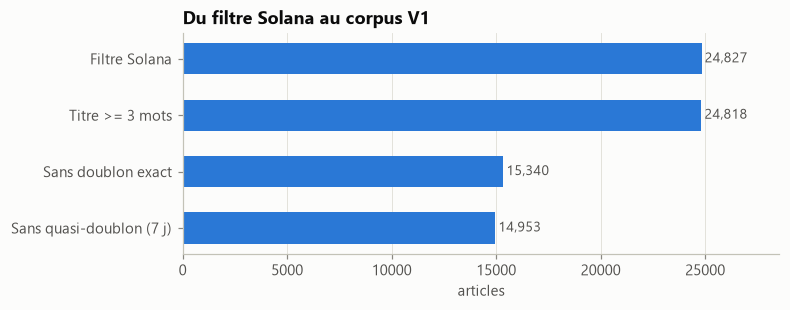

In [2]:
funnel = pd.Series({
    "Chargés (2 sources)": sum(stats["1_loaded"].values()),
    "Titre non vide": stats["2_non_empty_title"],
    "Date valide (2020–2025)": stats["3_valid_dates"],
    "Filtre Solana": sum(stats["4_solana_filter"].values()),
    "Titre >= 3 mots": stats["5_min_words"],
    "Sans doublon exact": stats["6_exact_dedup"],
    "Sans quasi-doublon (7 j)": stats["7_near_dedup"],
})
display(funnel.to_frame("articles").assign(removed=lambda t: (-t.articles.diff()).fillna(0).astype(int)))

f = funnel.iloc[3:]
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.barh(f.index[::-1], f.values[::-1], color=SERIES[0], height=0.55)
for y, v in enumerate(f.values[::-1]):
    ax.text(v + 150, y, f"{v:,}", va="center", color=INK_2, fontsize=9)
ax.set_title("Du filtre Solana au corpus V1"); ax.grid(axis="y", visible=False)
ax.set_xlim(0, f.max() * 1.15); ax.set_xlabel("articles")
save(fig, "eda_01_funnel")

Le dédoublonnage exact retire environ 9 500 lignes : CryptoVision répète le même article
pour chaque crypto citée (champ `Coin Type`).

## 2. Provenance : jeux de données et médias

,articles
source_dataset,
coindesk_hf,10472
cryptovision,4481


69 médias distincts ; top 15 = 69% du corpus


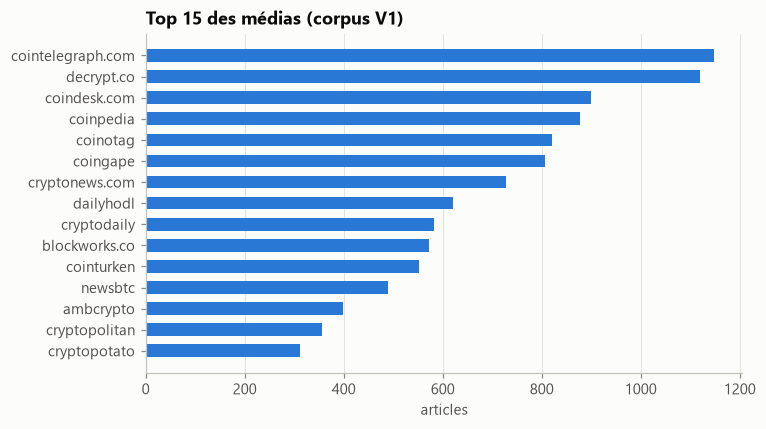

In [3]:
display(df.source_dataset.value_counts().to_frame("articles"))
top = df.outlet.value_counts().head(15)
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(top.index[::-1], top.values[::-1], color=SERIES[0], height=0.6)
ax.set_title("Top 15 des médias (corpus V1)"); ax.grid(axis="y", visible=False); ax.set_xlabel("articles")
save(fig, "eda_02_outlets")
print(f"{df.outlet.nunique()} médias distincts ; top 15 = {top.sum() / len(df):.0%} du corpus")

## 3. Couverture temporelle (articles par mois)

Mois avec < 30 articles : ['2020-03', '2020-04', '2020-05', '2020-06', '2020-07', '2020-08', '2020-09', '2020-10', '2020-12', '2021-01', '2021-02', '2021-03', '2021-04', '2021-05']


,articles
published_at_utc,
2020,41
2021,839
2022,1606
2023,2228
2024,8234
2025,2005


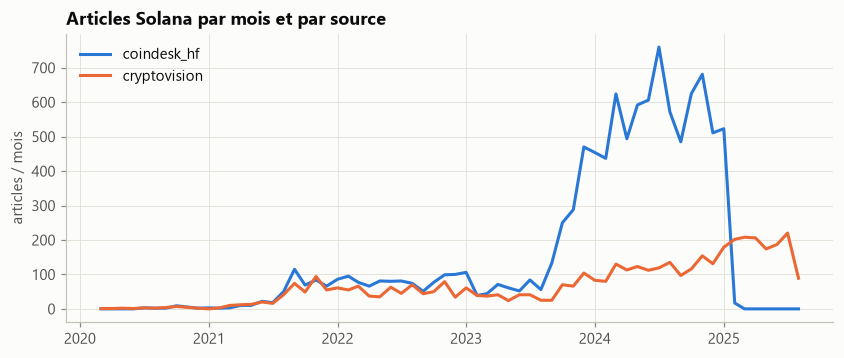

In [4]:
monthly = (df.assign(month=df.published_at_utc.dt.tz_localize(None).dt.to_period("M").dt.to_timestamp())
             .groupby(["month", "source_dataset"]).size().unstack(fill_value=0))
fig, ax = plt.subplots(figsize=(9, 3.4))
for src in monthly.columns:
    ax.plot(monthly.index, monthly[src], color=SOURCE_COLORS[src], label=src)
ax.set_title("Articles Solana par mois et par source"); ax.set_ylabel("articles / mois")
ax.legend(loc="upper left"); ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
save(fig, "eda_03_monthly")
tot = monthly.sum(axis=1)
print("Mois avec < 30 articles :", [m.strftime("%Y-%m") for m in tot[tot < 30].index])
display(df.published_at_utc.dt.year.value_counts().sort_index().to_frame("articles"))

**Point d'attention :** 2024 représente plus de la moitié du corpus (pic de la source CoinDesk HF,
qui s'arrête début 2025 ; CryptoVision couvre jusqu'à août 2025). D'où l'échantillonnage
**stratifié par mois** pour l'annotation.

## 4. Longueur des titres

,count,mean,std,min,25%,50%,75%,max
n_words,14953.0,12.0,3.4,3.0,10.0,12.0,14.0,38.0
n_chars,14953.0,75.1,20.9,16.0,61.0,72.0,86.0,232.0


Titres <= 5 mots :

 131


['Current Trends in Cryptocurrency Prices',
 'Overhyped Cryptocurrencies in 2023',
 'Magic Eden Company Intelligence',
 'Solana ‘roast’ reveals painful truths',
 'Grayscale launches Pyth investment fund',
 'How Are Altcoins Performing Today?',
 'Solana Investors Monitor Price Fluctuations',
 'Lily Liu: Solana’s Powerhouse Ambassador']

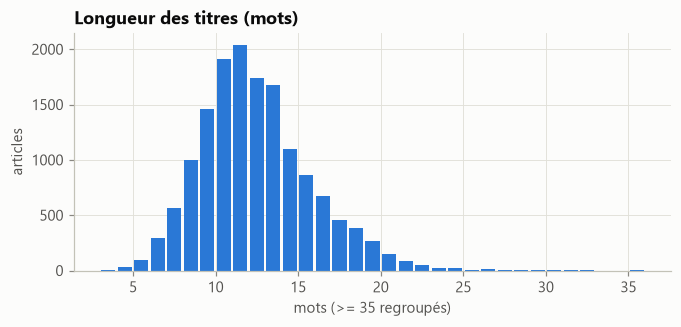

In [5]:
df["n_chars"] = df.title.str.len()
display(df[["n_words", "n_chars"]].describe().T.round(1))
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.hist(df.n_words.clip(upper=35), bins=range(3, 37), color=SERIES[0], rwidth=0.85)
ax.set_title("Longueur des titres (mots)"); ax.set_xlabel("mots (>= 35 regroupés)"); ax.set_ylabel("articles")
save(fig, "eda_04_title_length")
print("Titres <= 5 mots :", (df.n_words <= 5).sum())
df[df.n_words <= 5].title.sample(8, random_state=42).tolist()

## 5. Où Solana est-il mentionné ?

In [6]:
display(df.solana_in_title.value_counts(normalize=True).rename({True: "dans le titre", False: "description seule"}).to_frame("part").round(3))
terms = df.solana_terms.str.split("|").explode().replace("", pd.NA).dropna()
display(terms.value_counts().head(15).to_frame("titres"))
print("Exemples « description seule » :")
df[~df.solana_in_title].title.sample(8, random_state=1).tolist()

,part
solana_in_title,
dans le titre,0.799
description seule,0.201


,titres
solana_terms,
Solana,9662
SOL,3714
BONK,312
Bonk,189
Magic Eden,174
Pump.fun,171
$SOL,105
SOLANA,105
Raydium,73


Exemples « description seule » :


['HUGO Meme Coin Unveils AI-Driven Transparency Tool as Multi-Chain Expansion Begins',
 'Crypto Market Blooms With Activity as Active Addresses Hit an ATH',
 'Crypto Prices Today May 3: Bitcoin Nears $60K As Ethereum & Other Altcoins Recover',
 'FOMO HOUR 184 - PUNKS ARE FLYING!',
 'Is NFT Winter Over? Prices Climb as Bitcoin and Ethereum Surge',
 'BlackRock’s Ethereum ETF ETHA Just Changed the ETF Landscape Forever',
 'Fantom Eyeing Towards Immediate Resistance; Can FTM Breach 100 EMA?',
 'Crypto Prices Today, Nov 29: BTC Nears $97K, XRP Jumps 14%, ALGO Soars 25%']

## 6. Termes fréquents
Pour la lecture seulement, on retire les mots vides anglais ici (ce n'est **pas** le prétraitement
des modèles : la V4 conserve négations, casse et tickers).

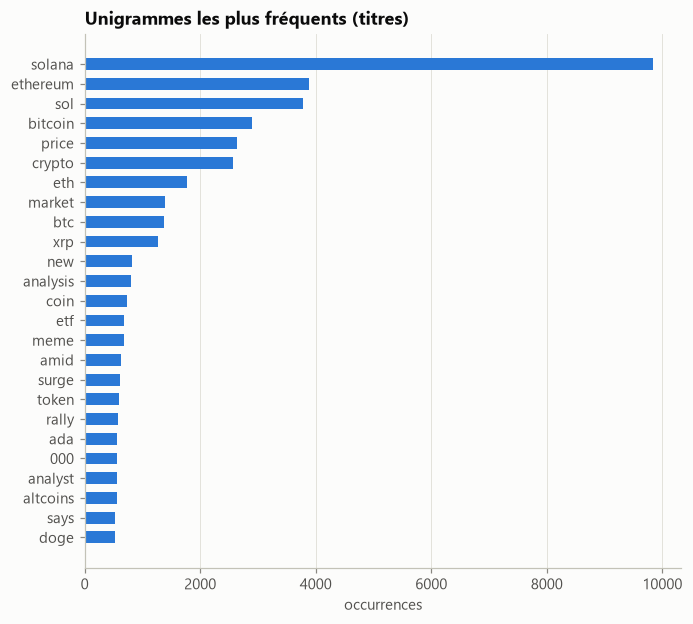

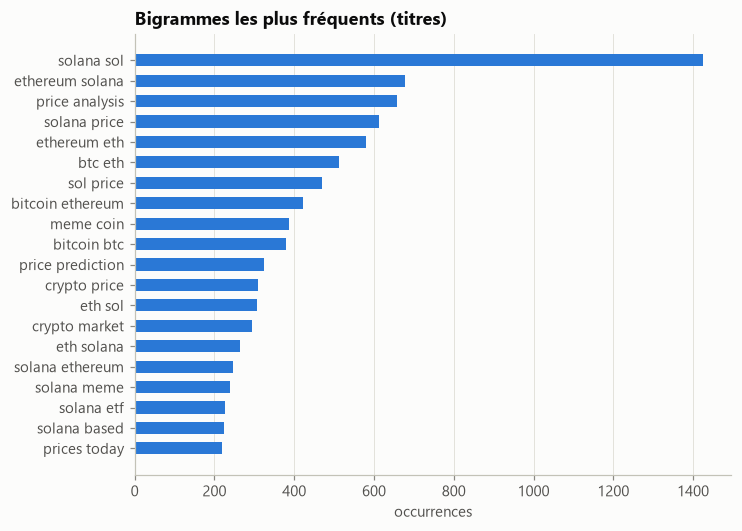

In [7]:
for ngram, k in [((1, 1), 25), ((2, 2), 20)]:
    cv = CountVectorizer(ngram_range=ngram, stop_words="english", token_pattern=r"(?u)\$?\b\w[\w.]+\b", min_df=5)
    X = cv.fit_transform(df.title)
    freq = pd.Series(X.sum(axis=0).A1, index=cv.get_feature_names_out()).sort_values(ascending=False).head(k)
    fig, ax = plt.subplots(figsize=(7, 0.22 * k + 0.8))
    ax.barh(freq.index[::-1], freq.values[::-1], color=SERIES[0], height=0.6)
    ax.set_title(f"{'Unigrammes' if ngram == (1, 1) else 'Bigrammes'} les plus fréquents (titres)")
    ax.grid(axis="y", visible=False); ax.set_xlabel("occurrences")
    save(fig, f"eda_06_top_{'uni' if ngram == (1, 1) else 'bi'}grams")

## 7. Jargon et difficultés attendues (V4 §1)

In [8]:
import warnings
warnings.filterwarnings("ignore", message="This pattern")
patterns = {
    "airdrop": r"(?i)\bairdrops?\b", "outage / halt": r"(?i)\b(outage|halt(ed|s)?|downtime|congestion)\b",
    "hack / exploit": r"(?i)\b(hack(ed)?|exploit(ed)?|drain(ed)?|scam)\b", "TVL": r"\bTVL\b",
    "ETF": r"\bETFs?\b", "memecoin": r"(?i)\bmeme ?coins?\b", "négation (not/no/never…)": r"(?i)\b(not|no|never|isn't|won't|can't|doesn't)\b",
    "question (?)": r"\?", "prix chiffré ($…)": r"\$\d", "liste multi-actifs (>= 3 tickers)": r"(?:\b[A-Z]{2,5}\b,\s*){2,}",
}
jargon = pd.Series({k: df.title.str.contains(p, regex=True).mean() for k, p in patterns.items()}).sort_values(ascending=False)
display((jargon * 100).round(1).to_frame("% des titres"))

,% des titres
prix chiffré ($…),22.9
question (?),13.3
memecoin,6.6
liste multi-actifs (>= 3 tickers),6.2
ETF,5.6
négation (not/no/never…),1.3
hack / exploit,1.0
airdrop,0.9
outage / halt,0.7
TVL,0.5


Ces familles alimenteront le guide d'annotation (règles pour les cas limites) puis la grille
d'analyse d'erreurs de la semaine 5.

## 8. Recouvrement avec DLT-Sentiment-News (risque de fuite)

In [9]:
print(f"{df.in_dlt.sum():,} titres du corpus V1 ({df.in_dlt.mean():.1%}) existent aussi dans DLT-Sentiment-News.")
display(df[df.in_dlt].published_at_utc.dt.year.value_counts().sort_index().to_frame("titres en commun"))

753 titres du corpus V1 (5.0%) existent aussi dans DLT-Sentiment-News.


,titres en commun
published_at_utc,
2021,121
2022,243
2023,138
2024,207
2025,44


Décision (journal du 2026-11-14) : au moment du split, tout titre de (a) identique ou quasi
identique à un titre Solana de validation/test est retiré de (a).

## 9. Bilan du jalon 1

In [10]:
cfg = load_config()["corpus"]
summary = pd.Series({
    "articles (V1)": f"{len(df):,}",
    "objectif O1 (>= 1 500)": "atteint" if len(df) >= cfg["target_min_articles"] else "NON atteint",
    "période": f"{df.published_at_utc.min():%Y-%m} -> {df.published_at_utc.max():%Y-%m}",
    "Solana dans le titre": f"{df.solana_in_title.mean():.0%}",
    "avec description": f"{df.description.notna().mean():.0%}",
    "médias": df.outlet.nunique(),
    "en commun avec DLT": f"{df.in_dlt.sum():,}",
})
summary.to_frame("valeur")

,valeur
articles (V1),"14,953"
objectif O1 (>= 1 500),atteint
période,2020-03 -> 2025-08
Solana dans le titre,80%
avec description,93%
médias,69
en commun avec DLT,753
